In [1]:
import numpy as np
import cv2
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

def gmm_image_segmentation(image, n_components=3, covariance_type='full', random_state=42):

    # Get image dimensions
    height, width = image.shape[:2]
    channels = 1 if len(image.shape) == 2 else image.shape[2]

    # Reshape image to a 2D array of pixels (features: intensity or RGB)
    data = image.reshape(-1, channels)

    # Fit GMM
    gmm = GaussianMixture(n_components=n_components, covariance_type=covariance_type, random_state=random_state)
    gmm.fit(data)

    # Predict labels
    labels = gmm.predict(data)

    # Reshape labels back to image shape
    labels = labels.reshape(height, width)

    return labels



In [8]:
# Example usage with visualization
from skimage import io

# Create a sample synthetic image (for demonstration)
height, width = 100, 100
image = np.zeros((height, width, 3), dtype=np.uint8)
image[20:50, 20:50] = [255, 0, 0]  # Red square
image[60:90, 60:90] = [0, 255, 0]  # Green square

# Load image and convert it to double precision (float in Python)
image = io.imread('/content/sample_data/testimage4.jpg')  # Replace with your image file path

# Run GMM segmentation
n_components = 4  # Number of segments
labels = gmm_image_segmentation(image, n_components=n_components)

# Convert labels to a segmented image for visualization (assign random colors)
colors = np.random.randint(0, 256, size=(n_components, 3))
segmented_image = colors[labels]

# Print shape and unique labels
print("Segmented image shape:", segmented_image.shape)
print("Unique segment labels:", np.unique(labels))



Segmented image shape: (763, 894, 3)
Unique segment labels: [0 1 2 3 4]


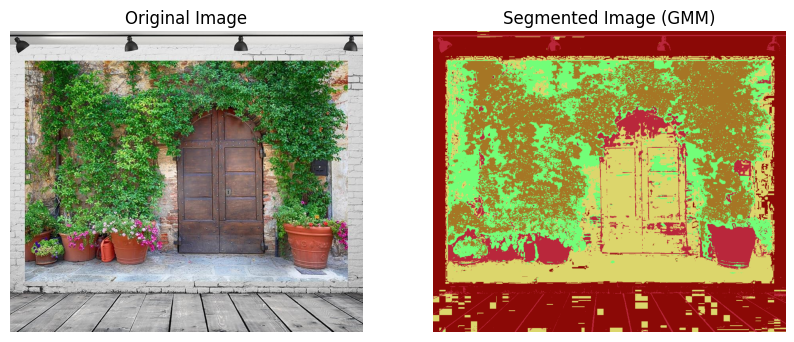

In [9]:
# Visualize original and segmented images
plt.figure(figsize=(10, 5))

# Plot original image
plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis('off')

# Plot segmented image
plt.subplot(1, 2, 2)
plt.imshow(segmented_image)
plt.title("Segmented Image (GMM)")
plt.axis('off')

# Display the plot
plt.show()